# Milestone 2 – Improve: experiments and results

By default this notebook **loads the stored results** from `results_m2/` and shows the results
table and figures, with no training. Set `RERUN = True` to rerun every experiment with
`run_m2.sh`. That takes several hours on a laptop RTX 5050 (the augmented LOSO runs are the slowest). Finished subjects
are skipped.

The data split is the one from Milestone 1 (`src/prepare_data.py`):
- **train**: session `0train`, runs 0–4
- **valid**: run 5
- **test**: session `1test`

In LOSO, training and validation use the other 8 subjects, and the test is the held-out
subject's `1test`. Each model trains for 100 epochs. The **epoch with the best validation
accuracy** is restored, and the test set is evaluated once.

In [1]:
RERUN = False

import os, sys, json, glob, subprocess
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
DATA_NPZ = '../data_npz'   # cached arrays from: python src/prepare_data.py --subjects all --save-npz ../data_npz

if RERUN:
    subprocess.run(['bash', 'run_m2.sh', sys.executable, DATA_NPZ], check=True)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
sys.path.insert(0, 'src')
import summarize_m2 as S

## Results table

In [2]:
df = S.load('results_m2')
res = S.experiment_rows(df)
display(Markdown(S.to_markdown(res)))

| ID | Protocol | Change | Seeds | Valid acc (%) | Test acc (%), valid-selected | Δ vs. baseline (pp) | Test acc (%), after 100 epochs | Train acc (%) | Mean selected epoch |
|---|---|---|---|---|---|---|---|---|---|
| B0 | within | baseline: ShallowFBCSPNet (M1 model, trial-wise, valid-selected) | 3 | 68.67 ± 2.07 | **60.58 ± 1.33** | +0.00 | 64.03 ± 0.10 | 99.6 | 40 |
| E1 | within | model → EEGNet | 3 | 59.03 ± 0.93 | **59.61 ± 0.71** | -0.98 | 60.62 ± 0.49 | 91.1 | 81 |
| E2 | within | model → EEGConformer | 3 | 64.04 ± 0.48 | **58.81 ± 1.49** | -1.77 | 61.27 ± 1.05 | 86.0 | 59 |
| E3 | within | + data augmentation | 3 | 69.37 ± 1.04 | **65.05 ± 1.18** | +4.46 | 66.55 ± 1.08 | 99.8 | 64 |
| E4 | within | + Euclidean alignment | 3 | 70.99 ± 1.07 | **70.77 ± 1.12** | +10.19 | 71.48 ± 0.66 | 100.0 | 55 |
| L0 | loso | LOSO baseline: ShallowFBCSPNet, unseen subject | 3 | 63.78 ± 0.12 | **43.74 ± 0.56** | +0.00 | 43.49 ± 0.52 | 98.9 | 79 |
| L1 | loso | + Euclidean alignment | 3 | 68.28 ± 1.07 | **50.87 ± 0.69** | +7.14 | 51.38 ± 0.28 | 100.0 | 34 |
| L2 | loso | EEGNet + Euclidean alignment (vs. L1: model) | 3 | 65.63 ± 0.38 | **51.54 ± 1.36** | +7.81 | 52.47 ± 1.00 | 84.6 | 54 |
| L3 | loso | + Euclidean alignment + augmentation (vs. L1: augmentation) | 3 | 69.94 ± 0.54 | **53.59 ± 0.95** | +9.85 | 53.31 ± 1.18 | 99.9 | 49 |
| L4 | loso | EEGConformer + Euclidean alignment (vs. L1: model) | 1 | 66.61 | **50.93** | +7.19 | 50.42 | 98.1 | 57 |

Per-subject test accuracy (%), mean over seeds:

| ID | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| B0 | 61.9 | 40.0 | 78.1 | 56.2 | 43.3 | 42.8 | 78.6 | 72.2 | 72.0 |
| E1 | 67.5 | 43.8 | 81.2 | 52.9 | 33.2 | 36.7 | 70.4 | 71.6 | 79.2 |
| E2 | 65.9 | 37.5 | 78.6 | 59.6 | 37.3 | 40.0 | 72.7 | 69.7 | 68.1 |
| E3 | 71.6 | 41.5 | 84.5 | 64.0 | 46.4 | 46.4 | 80.0 | 74.8 | 76.2 |
| E4 | 80.4 | 50.0 | 89.0 | 62.6 | 59.1 | 45.1 | 85.4 | 84.1 | 81.0 |
| L0 | 65.7 | 30.2 | 58.3 | 35.9 | 27.8 | 31.6 | 32.2 | 56.0 | 55.9 |
| L1 | 68.6 | 33.0 | 68.2 | 46.3 | 35.6 | 44.4 | 39.5 | 62.7 | 59.5 |
| L2 | 67.8 | 33.1 | 72.2 | 40.7 | 36.8 | 43.9 | 44.0 | 66.1 | 59.3 |
| L3 | 72.9 | 37.6 | 69.4 | 47.6 | 37.4 | 44.6 | 43.4 | 67.5 | 61.9 |
| L4 | 69.1 | 29.9 | 69.1 | 44.4 | 36.5 | 44.8 | 39.6 | 63.9 | 61.1 |


**Valid-selected** is the primary result: the epoch with the best validation accuracy. **After
100 epochs** is the fixed-budget rule of Milestone 1. Both rules are fixed in advance, and
neither uses test data. Values are the mean over the 9 subjects (LOSO: 9 folds), then mean ± std
over seeds.

## Overview

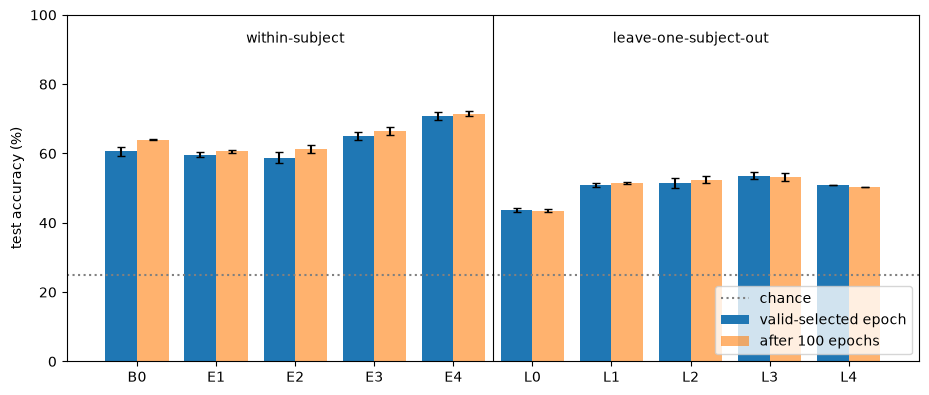

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(res))
ax.bar(x - 0.2, res.test_mean, 0.4, yerr=res.test_std.fillna(0), capsize=3, label='valid-selected epoch')
ax.bar(x + 0.2, res.last_mean, 0.4, yerr=res.last_std.fillna(0), capsize=3, label='after 100 epochs', alpha=0.6)
ax.axhline(25, color='gray', ls=':', label='chance')
ax.axvline(4.5, color='k', lw=0.8)
ax.text(2, 92, 'within-subject', ha='center'); ax.text(7, 92, 'leave-one-subject-out', ha='center')
ax.set_xticks(x, res.id); ax.set_ylim(0, 100); ax.set_ylabel('test accuracy (%)')
ax.legend(loc='lower right'); plt.show()

## Per subject: within-subject vs. new user (LOSO)

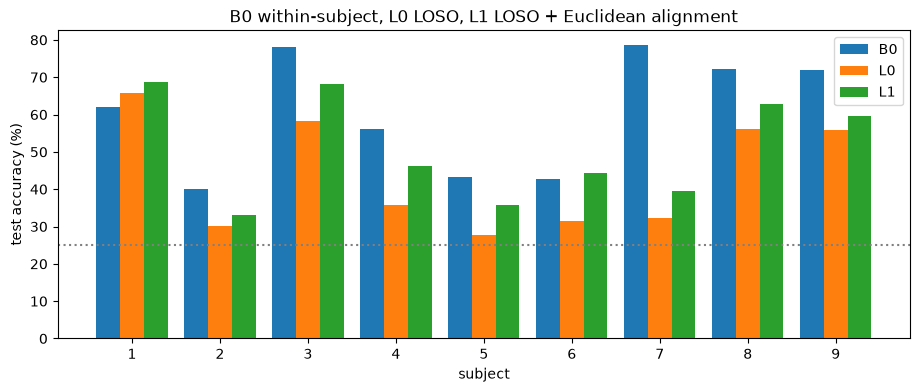

In [4]:
subj = range(1, 10)
fig, ax = plt.subplots(figsize=(11, 4))
for k, eid in enumerate(['B0', 'L0', 'L1']):
    if eid in set(res.id):
        ps = res.set_index('id').loc[eid, 'per_subject']
        ax.bar(np.array(subj) + (k - 1) * 0.27, [ps[s] for s in subj], 0.27, label=eid)
ax.axhline(25, color='gray', ls=':')
ax.set_xticks(list(subj)); ax.set_xlabel('subject'); ax.set_ylabel('test accuracy (%)')
ax.legend(); ax.set_title('B0 within-subject, L0 LOSO, L1 LOSO + Euclidean alignment'); plt.show()

## Validation curves (mean over subjects / folds, seed 20200220)

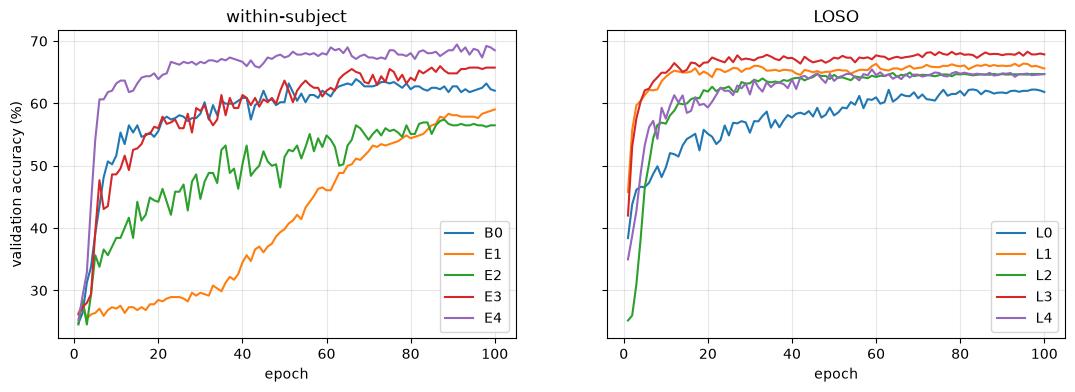

In [5]:
def curves(protocol, model, ea, aug, seed=20200220):
    files = glob.glob(f"results_m2/{protocol}_{model}{'_ea' if ea else ''}{'_aug' if aug else ''}_seed{seed}/subject_*.json")
    h = [pd.DataFrame(json.load(open(f))['history']) for f in files]
    return pd.concat(h).groupby('epoch')[['valid_acc', 'train_loss', 'valid_loss']].mean() if h else None

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, ids in zip(axes, [['B0', 'E1', 'E2', 'E3', 'E4'], ['L0', 'L1', 'L2', 'L3', 'L4']]):
    for eid in ids:
        e = [x for x in S.EXPERIMENTS if x[0] == eid][0]
        c = curves(*e[1:5])
        if c is not None:
            ax.plot(c.index, 100 * c.valid_acc, label=eid)
    ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
axes[0].set_ylabel('validation accuracy (%)'); axes[0].set_title('within-subject'); axes[1].set_title('LOSO')
plt.show()

## Confusion matrices (all subjects pooled, seed 20200220)

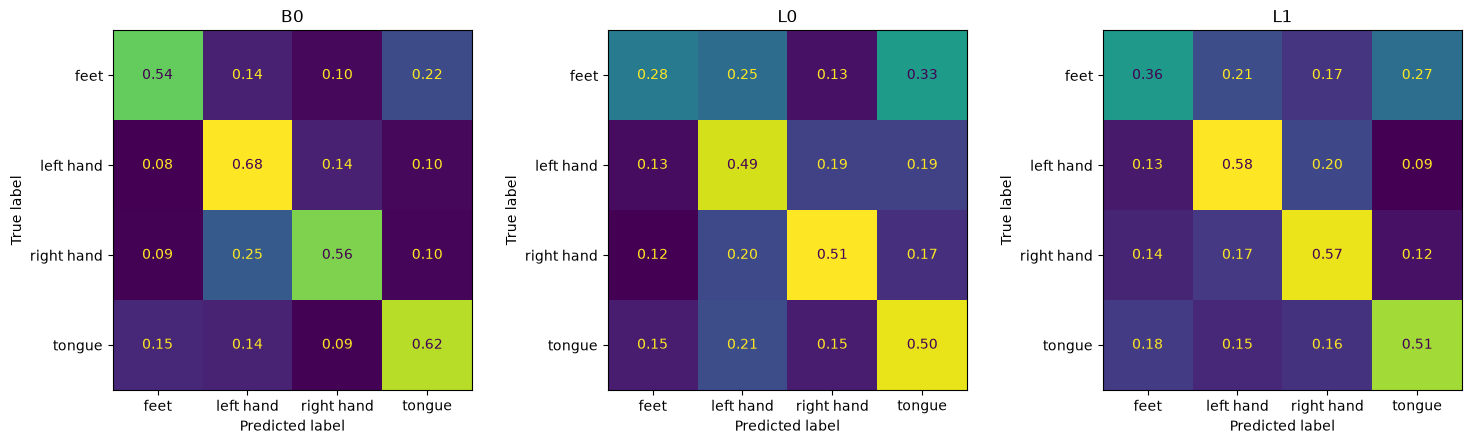

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
classes = ['feet', 'left hand', 'right hand', 'tongue']
show = [('B0', 'within_shallow'), ('L0', 'loso_shallow'), ('L1', 'loso_shallow_ea')]
fig, axes = plt.subplots(1, len(show), figsize=(15, 4.5))
for ax, (eid, run) in zip(axes, show):
    yt, yp = [], []
    for f in sorted(glob.glob(f'results_m2/{run}_seed20200220/subject_*.json')):
        r = json.load(open(f)); yt += r['y_true']; yp += r['y_pred']
    if yt:
        ConfusionMatrixDisplay.from_predictions(yt, yp, display_labels=classes, normalize='true',
                                                values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(eid)
plt.tight_layout(); plt.show()